In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")

plt.rcParams['figure.figsize'] = (10, 5)

plt.rcParams['font.size'] = 11

In [3]:
df = pd.read_csv("../data/delhi_metro_ridership.csv")

df['Date'] = pd.to_datetime(df['Date'])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (148500, 16)


In [4]:
df.head()

,TripID,Date,From_Station,To_Station,Distance_km,Fare,Cost_per_passenger,Passengers,Ticket_Type,Remarks,Year,Month,Month_Name,Day,Day_Number,Is_Weekend
0,59771,2022-05-08,Inderlok,Kashmere Gate,12.94,77.99,18.27,13.0,Smart Card,maintenance,2022,5,May,Sunday,6,True
1,21363,2023-01-12,Model Town,Dilshad Garden,2.33,35.89,83.71,15.0,Tourist Card,maintenance,2023,1,January,Thursday,3,False
2,127325,2023-07-13,Kashmere Gate,Netaji Subhash Place,5.56,64.35,43.70,9.0,Single,off-peak,2023,7,July,Thursday,3,False
3,140510,2022-11-10,Chandni Chowk,Hauz Khas,4.02,144.13,14.98,27.0,Unknown,maintenance,2022,11,November,Thursday,3,False
4,144298,2022-11-06,Rajiv Chowk,Kalkaji Mandir,9.66,104.96,83.84,23.0,Single,off-peak,2022,11,November,Sunday,6,True


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148500 entries, 0 to 148499
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   TripID              148500 non-null  int64         
 1   Date                148500 non-null  datetime64[ns]
 2   From_Station        148500 non-null  object        
 3   To_Station          148500 non-null  object        
 4   Distance_km         148500 non-null  float64       
 5   Fare                148500 non-null  float64       
 6   Cost_per_passenger  148500 non-null  float64       
 7   Passengers          148500 non-null  float64       
 8   Ticket_Type         148500 non-null  object        
 9   Remarks             148500 non-null  object        
 10  Year                148500 non-null  int64         
 11  Month               148500 non-null  int64         
 12  Month_Name          148500 non-null  object        
 13  Day                 148500 no

In [6]:
df.describe()

,TripID,Date,Distance_km,Fare,Cost_per_passenger,Passengers,Year,Month,Day_Number
count,148500.000000,148500,148500.000000,148500.000000,148500.000000,148500.000000,148500.000000,148500.000000,148500.000000
mean,75026.497199,2023-07-02 07:23:42.836363520,5.490902,105.131920,62.472047,20.003522,2023.000680,6.518498,3.003993
min,1.000000,2022-01-01 00:00:00,0.500000,10.000000,5.000000,4.000000,2022.000000,1.000000,0.000000
25%,37532.750000,2022-10-01 00:00:00,1.940000,57.560000,33.680000,17.000000,2022.000000,4.000000,1.000000
50%,75053.500000,2023-07-03 00:00:00,3.965000,105.190000,62.540000,20.000000,2023.000000,7.000000,3.000000
75%,112527.250000,2024-04-01 00:00:00,7.420000,152.600000,91.180000,23.000000,2024.000000,10.000000,5.000000
max,150000.000000,2024-12-30 00:00:00,63.030000,200.000000,120.000000,41.000000,2024.000000,12.000000,6.000000
std,43300.752997,NaN,4.980190,54.881917,33.206367,4.468134,0.816371,3.442816,2.003197


In [7]:
# Phase 3 — Section 3.1: Overall Ridership Statistics
print("OVERALL RIDERSHIP STATISTICS")
print("--------------------------------")

print("Total Records:", len(df))
print("Total Passengers:", df['Passengers'].sum())
print("Average Passengers per Record:", round(df['Passengers'].mean(), 2))
print("Maximum Passengers in a Record:", df['Passengers'].max())
print("Minimum Passengers in a Record:", df['Passengers'].min())

OVERALL RIDERSHIP STATISTICS
--------------------------------
Total Records: 148500
Total Passengers: 2970523.0
Average Passengers per Record: 20.0
Maximum Passengers in a Record: 41.0
Minimum Passengers in a Record: 4.0


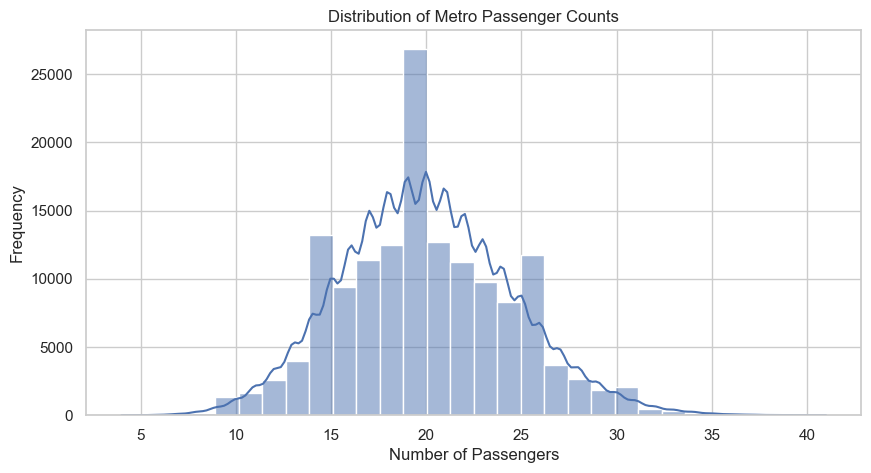

In [8]:
#Section 3.2 — Passenger Distribution (Histogram)
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Passengers',
    bins=30,
    kde=True
)

plt.title("Distribution of Metro Passenger Counts")
plt.xlabel("Number of Passengers")
plt.ylabel("Frequency")
plt.show()

In [9]:
#Section 3.3 — Daily Ridership Trends
daily_ridership = df.groupby('Date').agg(
    Total_Passengers=('Passengers', 'sum'),
    Total_Records=('TripID', 'count')
).reset_index()

daily_ridership.head()

,Date,Total_Passengers,Total_Records
0,2022-01-01,2938.0,141
1,2022-01-02,2592.0,129
2,2022-01-03,2473.0,125
3,2022-01-04,2794.0,142
4,2022-01-05,2798.0,139


In [10]:
print("Total Days:", len(daily_ridership))
print("Average Daily Passengers:", round(daily_ridership['Total_Passengers'].mean(), 2))
print("Maximum Daily Passengers:", daily_ridership['Total_Passengers'].max())
print("Minimum Daily Passengers:", daily_ridership['Total_Passengers'].min())

Total Days: 1095
Average Daily Passengers: 2712.81
Maximum Daily Passengers: 3745.0
Minimum Daily Passengers: 1934.0


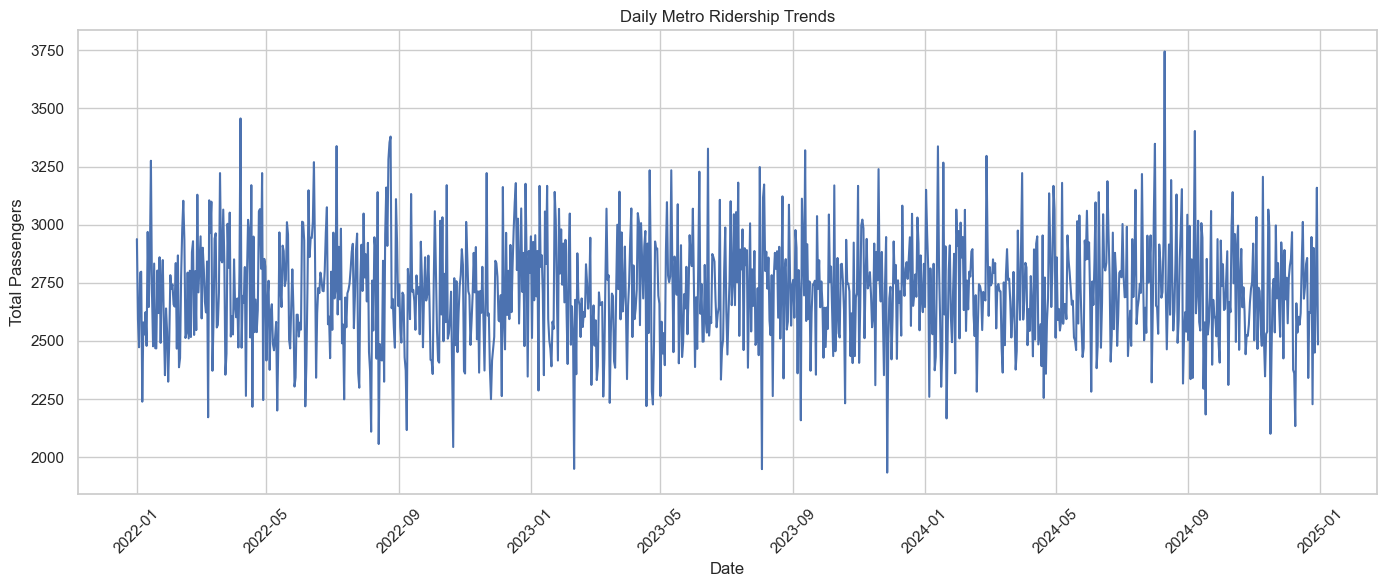

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_ridership['Date'],
    daily_ridership['Total_Passengers']
)

plt.title("Daily Metro Ridership Trends")
plt.xlabel("Date")
plt.ylabel("Total Passengers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
#January 2024 
jan_2024 = daily_ridership[
    (daily_ridership['Date'].dt.year == 2024) &
    (daily_ridership['Date'].dt.month == 1)
]

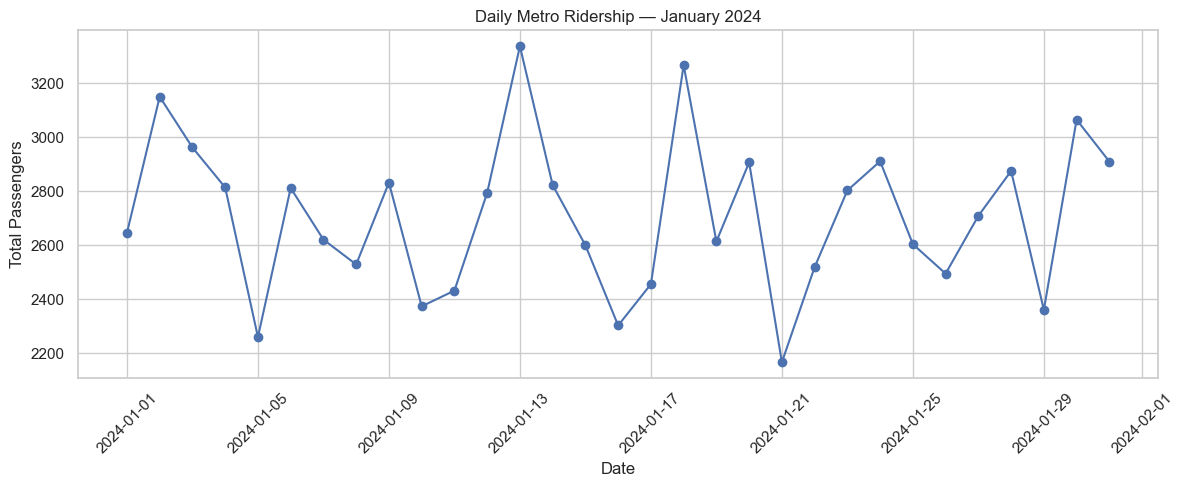

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    jan_2024['Date'],
    jan_2024['Total_Passengers'],
    marker='o',
    linewidth=1.5
)

plt.title("Daily Metro Ridership — January 2024")
plt.xlabel("Date")
plt.ylabel("Total Passengers")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
#Section 3.4 — Monthly Ridership Trends
monthly_ridership = df.groupby(
    df['Date'].dt.to_period('M')
).agg(
    Total_Passengers=('Passengers', 'sum'),
    Total_Records=('TripID', 'count')
).reset_index()

monthly_ridership['Date'] = monthly_ridership['Date'].dt.to_timestamp()

monthly_ridership.head()

,Date,Total_Passengers,Total_Records
0,2022-01-01,82029.0,4108
1,2022-02-01,76367.0,3810
2,2022-03-01,85580.0,4296
3,2022-04-01,82523.0,4120
4,2022-05-01,81308.0,4061


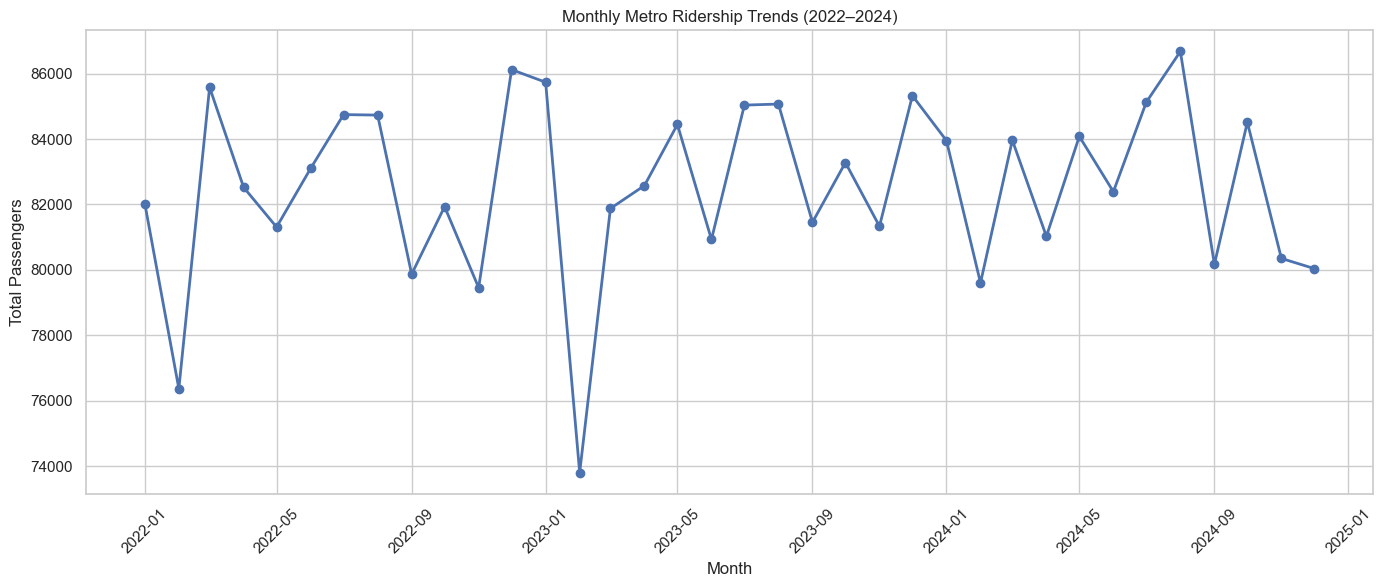

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_ridership['Date'],
    monthly_ridership['Total_Passengers'],
    marker='o',
    linewidth=2
)

plt.title("Monthly Metro Ridership Trends (2022–2024)")
plt.xlabel("Month")
plt.ylabel("Total Passengers")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
print("Total Months:", len(monthly_ridership))
print("Average Monthly Passengers:",
      round(monthly_ridership['Total_Passengers'].mean(), 2))

print("Highest Monthly Ridership:")
print(monthly_ridership.loc[
    monthly_ridership['Total_Passengers'].idxmax()
])

print("Lowest Monthly Ridership:")
print(monthly_ridership.loc[
    monthly_ridership['Total_Passengers'].idxmin()
])

Total Months: 36
Average Monthly Passengers: 82514.53
Highest Monthly Ridership:
Date                2024-08-01 00:00:00
Total_Passengers                86677.0
Total_Records                      4322
Name: 31, dtype: object
Lowest Monthly Ridership:
Date                2023-02-01 00:00:00
Total_Passengers                73802.0
Total_Records                      3687
Name: 13, dtype: object


In [17]:
#Section 3.5 — Year-wise Ridership Comparison
yearly_ridership = df.groupby('Year').agg(
    Total_Passengers=('Passengers', 'sum'),
    Total_Records=('TripID', 'count'),
    Average_Passengers=('Passengers', 'mean')
).reset_index()

yearly_ridership

,Year,Total_Passengers,Total_Records,Average_Passengers
0,2022,987765.0,49434,19.981490
1,2023,990867.0,49531,20.004987
2,2024,991891.0,49535,20.024044


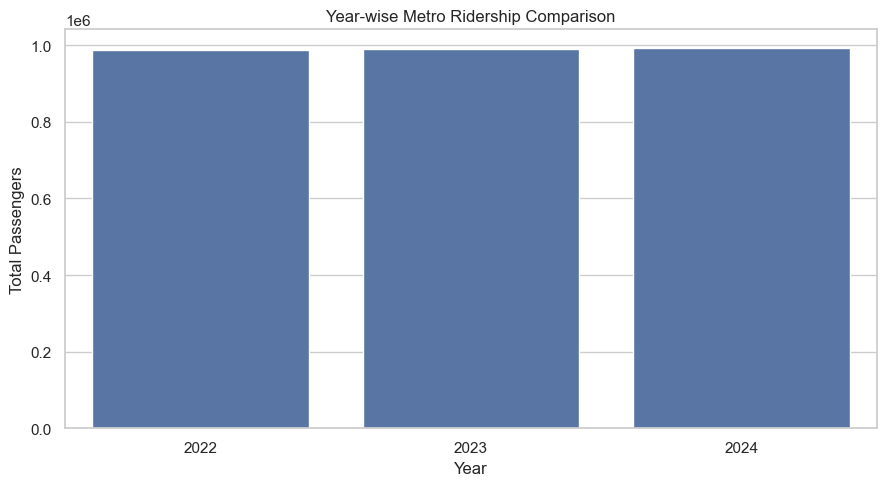

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_ridership,
    x='Year',
    y='Total_Passengers'
)

plt.title("Year-wise Metro Ridership Comparison")
plt.xlabel("Year")
plt.ylabel("Total Passengers")
plt.tight_layout()
plt.show()

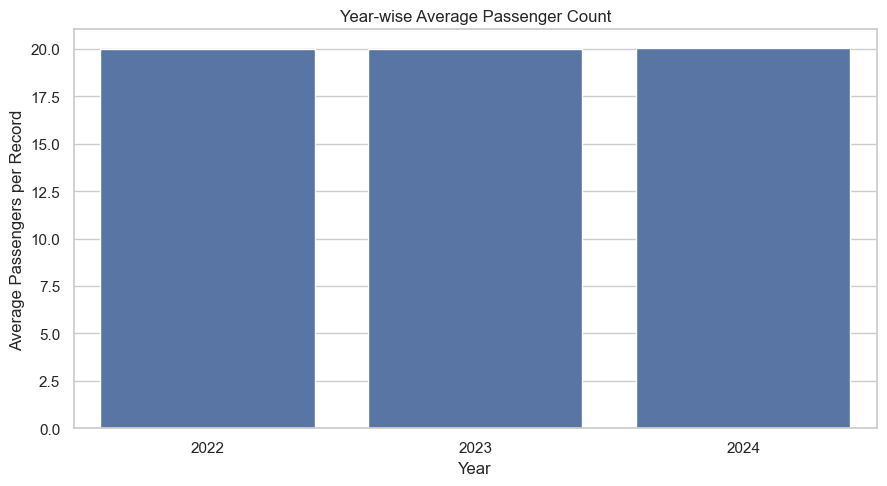

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_ridership,
    x='Year',
    y='Average_Passengers'
)

plt.title("Year-wise Average Passenger Count")
plt.xlabel("Year")
plt.ylabel("Average Passengers per Record")
plt.tight_layout()
plt.show()

In [20]:
print(yearly_ridership)

   Year  Total_Passengers  Total_Records  Average_Passengers
0  2022          987765.0          49434           19.981490
1  2023          990867.0          49531           20.004987
2  2024          991891.0          49535           20.024044


In [22]:
#Section 3.6 — Weekday vs. Weekend Ridership Analysis
daily_ridership['Day_Type'] = daily_ridership['Date'].dt.dayofweek.apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday'
)

daily_ridership.head()

,Date,Total_Passengers,Total_Records,Day_Type
0,2022-01-01,2938.0,141,Weekend
1,2022-01-02,2592.0,129,Weekend
2,2022-01-03,2473.0,125,Weekday
3,2022-01-04,2794.0,142,Weekday
4,2022-01-05,2798.0,139,Weekday


In [23]:
daytype_stats = daily_ridership.groupby('Day_Type').agg(
    Average_Daily_Passengers=('Total_Passengers', 'mean'),
    Median_Daily_Passengers=('Total_Passengers', 'median'),
    Total_Days=('Date', 'count'),
    Total_Passengers=('Total_Passengers', 'sum')
).reset_index()

daytype_stats

,Day_Type,Average_Daily_Passengers,Median_Daily_Passengers,Total_Days,Total_Passengers
0,Weekday,2706.323944,2699.0,781,2113639.0
1,Weekend,2728.929936,2713.0,314,856884.0


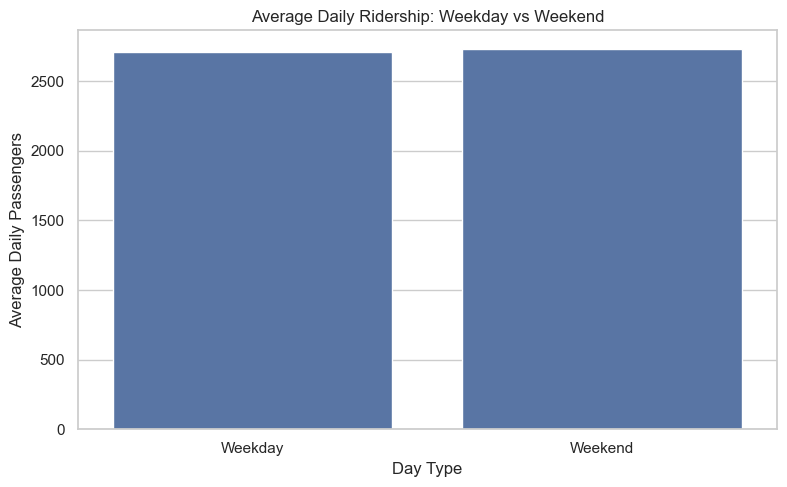

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=daytype_stats,
    x='Day_Type',
    y='Average_Daily_Passengers'
)

plt.title("Average Daily Ridership: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Passengers")
plt.tight_layout()
plt.show()

In [25]:
# Section 3.7 — Station-wise Ridership Analysis
from_station_stats = df.groupby('From_Station').agg(
    Total_Passengers=('Passengers', 'sum'),
    Total_Records=('TripID', 'count')
).reset_index()

from_station_stats = from_station_stats.sort_values(
    by='Total_Passengers',
    ascending=False
)

from_station_stats.head(10)

,From_Station,Total_Passengers,Total_Records
21,Rajiv Chowk,346204.0,17291
17,Noida City Centre,275554.0,13818
16,New Delhi,198767.0,9944
13,Mandi House,196492.0,9831
2,Central Secretariat,125830.0,6271
4,Dilshad Garden,125592.0,6293
9,Kalkaji Mandir,125430.0,6274
14,Model Town,124394.0,6187
3,Chandni Chowk,124251.0,6197
12,Laxmi Nagar,124168.0,6214


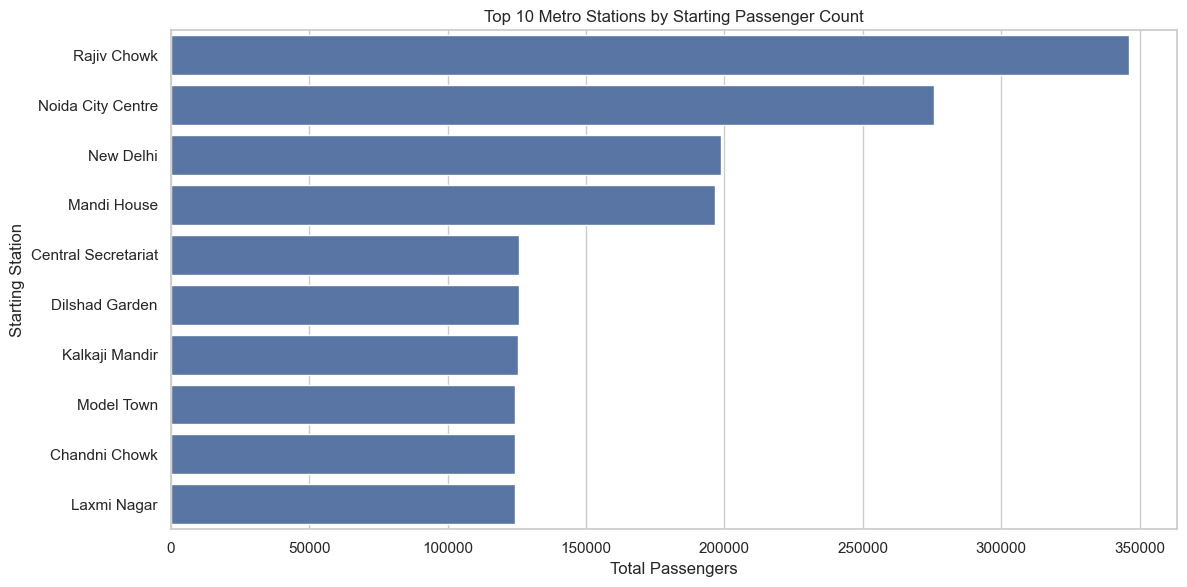

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=from_station_stats.head(10),
    x='Total_Passengers',
    y='From_Station'
)

plt.title("Top 10 Metro Stations by Starting Passenger Count")
plt.xlabel("Total Passengers")
plt.ylabel("Starting Station")
plt.tight_layout()
plt.show()

In [27]:
to_station_stats = df.groupby('To_Station').agg(
    Total_Passengers=('Passengers', 'sum'),
    Total_Records=('TripID', 'count')
).reset_index()

to_station_stats = to_station_stats.sort_values(
    by='Total_Passengers',
    ascending=False
)

to_station_stats.head(10)

,To_Station,Total_Passengers,Total_Records
11,Kirti Nagar,126579.0,6306
17,Noida City Centre,126101.0,6279
5,Hauz Khas,125827.0,6303
7,Janakpuri West,125610.0,6273
15,Netaji Subhash Place,124865.0,6240
4,Dilshad Garden,124535.0,6238
9,Kalkaji Mandir,124486.0,6211
10,Kashmere Gate,124397.0,6234
18,Old Delhi,124349.0,6251
1,Barakhamba Road,124193.0,6196


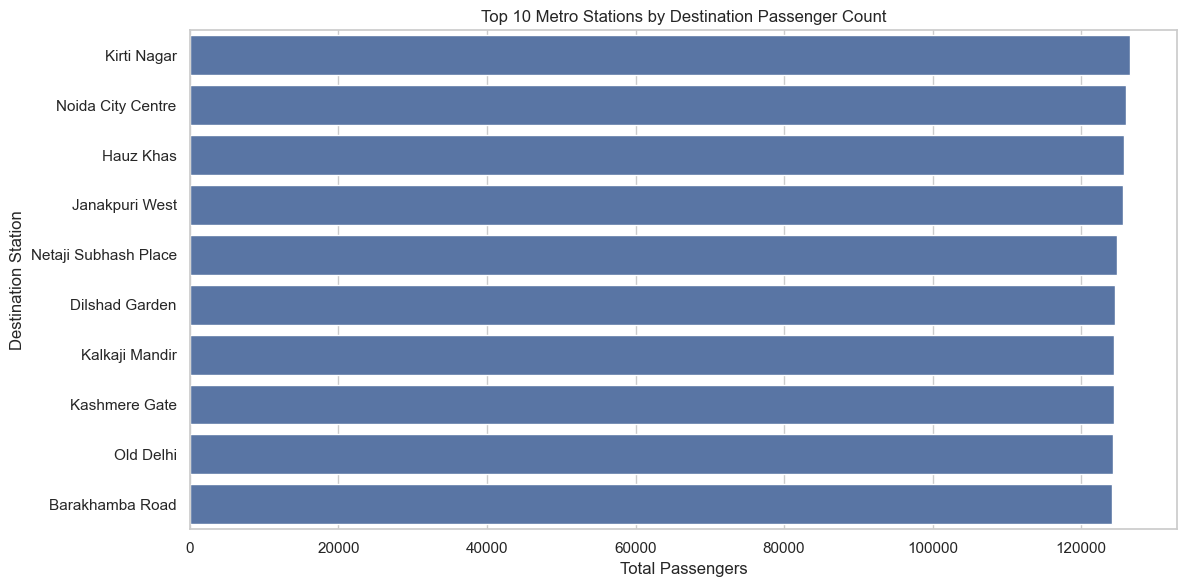

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=to_station_stats.head(10),
    x='Total_Passengers',
    y='To_Station'
)

plt.title("Top 10 Metro Stations by Destination Passenger Count")
plt.xlabel("Total Passengers")
plt.ylabel("Destination Station")
plt.tight_layout()
plt.show()

In [30]:
#Section 3.8 — Most Popular Metro Routes
route_stats = df.groupby(
    ['From_Station', 'To_Station']
).agg(
    Total_Passengers=('Passengers', 'sum'),
    Total_Records=('TripID', 'count'),
    Average_Passengers=('Passengers', 'mean')
).reset_index()

route_stats = route_stats.sort_values(
    by='Total_Passengers',
    ascending=False
)

route_stats.head(10)

,From_Station,To_Station,Total_Passengers,Total_Records,Average_Passengers
521,Rajiv Chowk,Noida City Centre,16223.0,810,20.028395
515,Rajiv Chowk,Kirti Nagar,15967.0,788,20.262690
507,Rajiv Chowk,Chandni Chowk,15928.0,799,19.934919
509,Rajiv Chowk,Hauz Khas,15802.0,787,20.078780
522,Rajiv Chowk,Old Delhi,15718.0,791,19.871049
526,Rajiv Chowk,Rajouri Garden,15388.0,769,20.010403
523,Rajiv Chowk,Pragati Maidan,15364.0,776,19.798969
504,Rajiv Chowk,Aiims,15257.0,756,20.181217
516,Rajiv Chowk,Laxmi Nagar,15066.0,751,20.061252
520,Rajiv Chowk,New Delhi,15018.0,751,19.997337


In [31]:
route_stats['Route'] = (
    route_stats['From_Station'] + ' → ' +
    route_stats['To_Station']
)

route_stats.head(10)

,From_Station,To_Station,Total_Passengers,Total_Records,Average_Passengers,Route
521,Rajiv Chowk,Noida City Centre,16223.0,810,20.028395,Rajiv Chowk → Noida City Centre
515,Rajiv Chowk,Kirti Nagar,15967.0,788,20.262690,Rajiv Chowk → Kirti Nagar
507,Rajiv Chowk,Chandni Chowk,15928.0,799,19.934919,Rajiv Chowk → Chandni Chowk
509,Rajiv Chowk,Hauz Khas,15802.0,787,20.078780,Rajiv Chowk → Hauz Khas
522,Rajiv Chowk,Old Delhi,15718.0,791,19.871049,Rajiv Chowk → Old Delhi
526,Rajiv Chowk,Rajouri Garden,15388.0,769,20.010403,Rajiv Chowk → Rajouri Garden
523,Rajiv Chowk,Pragati Maidan,15364.0,776,19.798969,Rajiv Chowk → Pragati Maidan
504,Rajiv Chowk,Aiims,15257.0,756,20.181217,Rajiv Chowk → Aiims
516,Rajiv Chowk,Laxmi Nagar,15066.0,751,20.061252,Rajiv Chowk → Laxmi Nagar
520,Rajiv Chowk,New Delhi,15018.0,751,19.997337,Rajiv Chowk → New Delhi


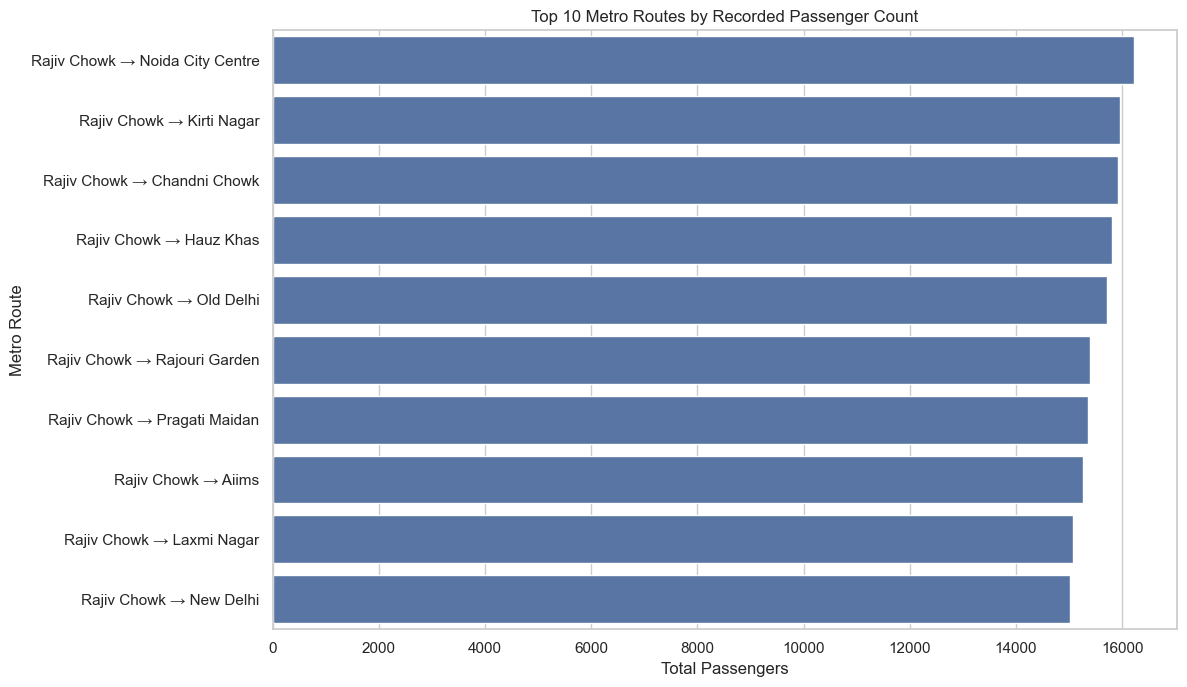

In [33]:
top_routes = route_stats.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_routes,
    x='Total_Passengers',
    y='Route'
)

plt.title("Top 10 Metro Routes by Recorded Passenger Count")
plt.xlabel("Total Passengers")
plt.ylabel("Metro Route")
plt.tight_layout()
plt.show()

In [34]:
frequent_routes = route_stats.sort_values(
    by='Total_Records',
    ascending=False
)

frequent_routes[['Route', 'Total_Records']].head(10)

,Route,Total_Records
521,Rajiv Chowk → Noida City Centre,810
507,Rajiv Chowk → Chandni Chowk,799
522,Rajiv Chowk → Old Delhi,791
515,Rajiv Chowk → Kirti Nagar,788
509,Rajiv Chowk → Hauz Khas,787
523,Rajiv Chowk → Pragati Maidan,776
526,Rajiv Chowk → Rajouri Garden,769
504,Rajiv Chowk → Aiims,756
520,Rajiv Chowk → New Delhi,751
516,Rajiv Chowk → Laxmi Nagar,751


In [35]:
#Section 3.9 — Peak vs. Off-Peak Ridership Analysis
df['Remarks'].value_counts()

Remarks
Unknown        26001
off-peak       24616
festival       24570
maintenance    24519
weekend        24464
peak           24330
Name: count, dtype: int64

In [36]:
df['Period'] = df['Remarks'].str.strip().str.lower().map({
    'peak': 'Peak',
    'off-peak': 'Off-Peak'
})

df['Period'].value_counts()

Period
Off-Peak    24616
Peak        24330
Name: count, dtype: int64

In [37]:
period_stats = df.dropna(subset=['Period']).groupby('Period').agg(
    Total_Passengers=('Passengers', 'sum'),
    Average_Passengers=('Passengers', 'mean'),
    Total_Records=('TripID', 'count')
).reset_index()

period_stats

,Period,Total_Passengers,Average_Passengers,Total_Records
0,Off-Peak,492409.0,20.003616,24616
1,Peak,486292.0,19.987341,24330


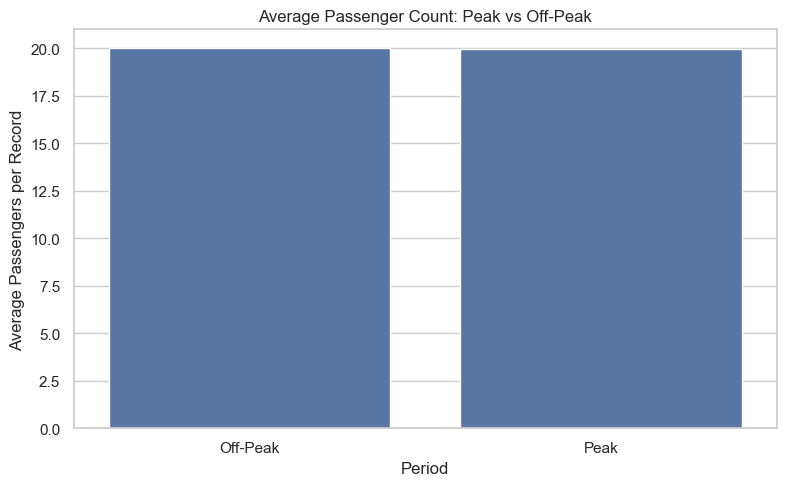

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=period_stats,
    x='Period',
    y='Average_Passengers'
)

plt.title("Average Passenger Count: Peak vs Off-Peak")
plt.xlabel("Period")
plt.ylabel("Average Passengers per Record")
plt.tight_layout()
plt.show()

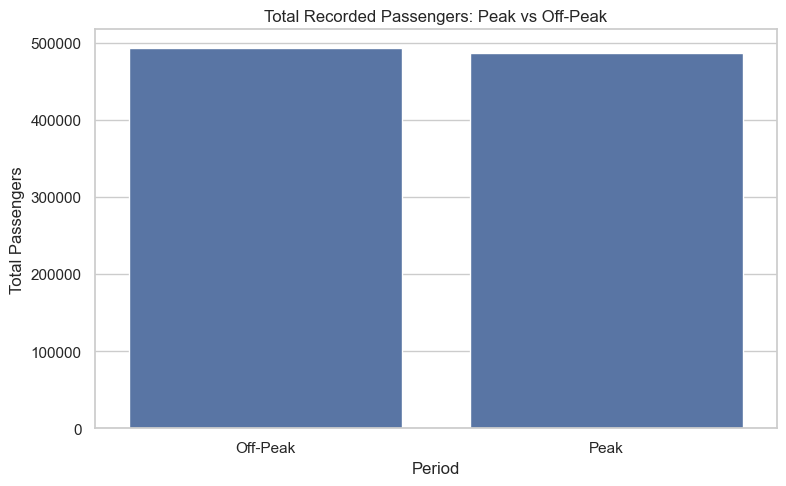

In [39]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=period_stats,
    x='Period',
    y='Total_Passengers'
)

plt.title("Total Recorded Passengers: Peak vs Off-Peak")
plt.xlabel("Period")
plt.ylabel("Total Passengers")
plt.tight_layout()
plt.show()

In [40]:
#Section 3.10 — Correlation Analysis
numerical_df = df[
    ['Distance_km', 'Fare', 'Cost_per_passenger', 'Passengers']
]

numerical_df.head()

,Distance_km,Fare,Cost_per_passenger,Passengers
0,12.94,77.99,18.27,13.0
1,2.33,35.89,83.71,15.0
2,5.56,64.35,43.70,9.0
3,4.02,144.13,14.98,27.0
4,9.66,104.96,83.84,23.0


In [41]:
correlation_matrix = numerical_df.corr()

correlation_matrix

,Distance_km,Fare,Cost_per_passenger,Passengers
Distance_km,1.000000,0.000178,-0.000699,-0.00173
Fare,0.000178,1.000000,-0.003412,-0.00049
Cost_per_passenger,-0.000699,-0.003412,1.000000,-0.00056
Passengers,-0.001730,-0.000490,-0.000560,1.00000


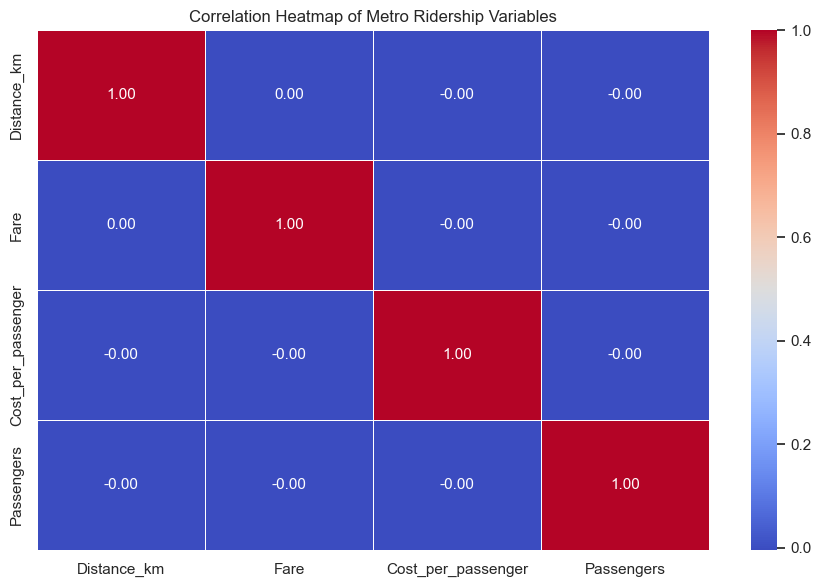

In [42]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Metro Ridership Variables")
plt.tight_layout()
plt.show()

In [43]:
print("Correlation with Passengers:")
print(
    correlation_matrix['Passengers']
    .sort_values(ascending=False)
)

Correlation with Passengers:
Passengers            1.00000
Fare                 -0.00049
Cost_per_passenger   -0.00056
Distance_km          -0.00173
Name: Passengers, dtype: float64
